# 05 - Greeks, parameter risk and delta hedging

A storage value is only useful to a desk with its risk: how much it moves with each forward month, with volatility and
with mean reversion, and how much of the P&L variance a forward hedge removes.

**Greeks by bump-and-revalue with common random numbers.** Each bumped valuation re-runs the full LSMC (regressions
and policy re-estimated) with the *same* seeds. With $V^{\pm}$ the bumped values,

$$\Delta_m = \frac{V(F_m(1+\epsilon)) - V(F_m(1-\epsilon))}{2\epsilon F_m}\ \text{[MWh]},\qquad
\Gamma = \frac{V(F+h) - 2V(F) + V(F-h)}{h^2},\qquad
\mathcal V_\sigma = \frac{\partial V}{\partial\sigma},\qquad \frac{\partial V}{\partial\kappa},$$

with $\epsilon = 1\,\%$, $h = 0.5$ EUR/MWh, $\pm 0.05$ on $\sigma$ and $\pm 0.5$ on $\kappa$. Standard errors come from
the per-path differences. $\Delta_m$ is the forward position (MWh) that offsets the storage's exposure to month $m$.

**Delta hedge.** Along each path the storage is hedged with monthly forwards, rebalanced monthly or weekly.
The hedge ratio uses the envelope theorem: since the policy is optimal it can be held fixed when differentiating, and
in the one-factor model $S_{t_k}\propto F(\tau,t_k)$, so

$$\Delta_m(\tau) = \frac{1}{F_m(\tau)}\,\mathbb E_\tau\Big[\sum_{k\in m} D_k\big(w_k-(1+\lambda)i_k\big)S_{t_k}\Big],$$

estimated by regression on $(X_\tau, v_\tau)$ over fit paths independent of the test paths. Details and the P&L
accounting are in `gasstorage.risk.delta_hedge`.

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir("..")

from gasstorage import plotting
from gasstorage.config import load_config
from gasstorage.models.one_factor import OneFactorModel
from gasstorage.risk.delta_hedge import delta_hedge, pnl_statistics
from gasstorage.risk.greeks import bump_parallel, lsmc_greeks
from gasstorage.storage.contract import build_inputs
from gasstorage.storage.lsmc import lsmc_value

plotting.apply_style()
CASES = {
    "market (EEX)": "configs/storage_default.yaml",
    "contango (SYNTHETIC)": "configs/storage_synthetic.yaml",
}
cfgs = {name: load_config(path) for name, path in CASES.items()}
N, LEVELS, SEEDS = 5000, 101, (12345, 67890)
inputs = {name: build_inputs(cfg, "weekly") for name, cfg in cfgs.items()}
models = {name: OneFactorModel.from_config(cfg.model) for name, cfg in cfgs.items()}

## 1. Greeks

In [2]:
greeks = {}
for name in CASES:
    t0 = time.perf_counter()
    greeks[name] = lsmc_greeks(inputs[name], models[name], N, SEEDS, n_levels=LEVELS)
    print(f"{name}: {time.perf_counter() - t0:.0f} s")
summary = pd.DataFrame(
    {
        name: {
            "value [MEUR]": g.base_value / 1e6,
            "value SE [MEUR]": g.base_se / 1e6,
            "parallel delta [GWh]": g.parallel_delta.value / 1e3,
            "parallel delta SE [GWh]": g.parallel_delta.se / 1e3,
            "gamma [MWh per EUR/MWh]": g.gamma.value,
            "gamma SE": g.gamma.se,
            "vega per +0.01 sigma [kEUR]": g.vega.value * 0.01 / 1e3,
            "vega SE [kEUR]": g.vega.se * 0.01 / 1e3,
            "dV/dkappa per +1/y [kEUR]": g.kappa_sensitivity.value / 1e3,
            "dV/dkappa SE [kEUR]": g.kappa_sensitivity.se / 1e3,
        }
        for name, g in greeks.items()
    }
)
summary.round(3)

market (EEX): 374 s


contango (SYNTHETIC): 367 s


,market (EEX),contango (SYNTHETIC)
value [MEUR],4.993,7.929
value SE [MEUR],0.081,0.078
parallel delta [GWh],128.963,91.970
parallel delta SE [GWh],3.341,2.981
gamma [MWh per EUR/MWh],8893.732,-10235.460
gamma SE,15713.290,9691.626
vega per +0.01 sigma [kEUR],120.462,44.506
vega SE [kEUR],1.826,1.070
dV/dkappa per +1/y [kEUR],238.603,40.714
dV/dkappa SE [kEUR],15.155,13.110


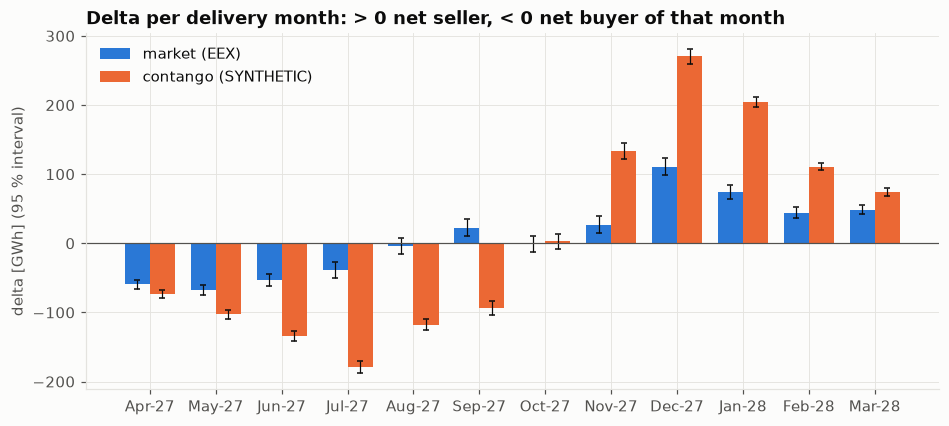

market (EEX)                  contango (SYNTHETIC)                 
             forward delta_gwh se_gwh              forward delta_gwh se_gwh
month                                                                      
2027-04        71.22    -59.60   3.06                30.00    -73.47   2.65
2027-05        66.94    -67.10   3.57                27.58   -102.83   3.29
2027-06        64.97    -53.32   4.44                25.84   -134.06   3.51
2027-07        63.87    -38.54   5.69                25.25   -179.14   4.23
2027-08        63.24     -3.46   5.78                26.00   -117.66   4.30
2027-09        62.69     22.82   6.35                27.92    -93.39   5.35
2027-10        60.45     -1.02   5.93                30.50      2.70   5.54
2027-11        60.16     26.81   6.10                33.08    133.34   5.72
2027-12        59.96    110.95   6.17                35.00    270.24   5.19
2028-01        57.77     74.05   5.09                35.75    204.52   3.93
2028-02        55.86     44.41   4.04                35.16    110.94   2.83
2028-03        54.26     48.35   3.33                33.42     74.52   2.90

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.2))
months = greeks["market (EEX)"].deltas.index
x = np.arange(len(months))
width = 0.38
for offset, color, (name, g) in zip(
    (-width / 2, width / 2), plotting.SERIES, greeks.items(), strict=False
):
    d = g.deltas.reindex(months)
    ax.bar(x + offset, d["delta_mwh"] / 1e3, width, color=color, label=name)
    ax.errorbar(
        x + offset,
        d["delta_mwh"] / 1e3,
        yerr=1.96 * d["se"] / 1e3,
        fmt="none",
        ecolor=plotting.TEXT_PRIMARY,
        lw=0.8,
        capsize=2,
    )
ax.axhline(0, color=plotting.TEXT_SECONDARY, lw=0.8)
ax.set_xticks(x, [m.strftime("%b-%y") for m in months])
ax.set_ylabel("delta [GWh] (95 % interval)")
ax.set_title("Delta per delivery month: > 0 net seller, < 0 net buyer of that month")
ax.legend(loc="upper left")
plotting.save_figure(fig, "05_monthly_deltas")
display(fig)
pd.concat(
    {
        n: g.deltas.assign(delta_gwh=g.deltas["delta_mwh"] / 1e3, se_gwh=g.deltas["se"] / 1e3)[
            ["forward", "delta_gwh", "se_gwh"]
        ]
        for n, g in greeks.items()
    },
    axis=1,
).round(2)

**Why common random numbers.** Without CRN, the up and down revaluations use independent paths and the
difference inherits the full Monte Carlo noise of both values. With CRN the paths are the same and only the response
to the bump remains.

In [4]:
inp, model = inputs["market (EEX)"], models["market (EEX)"]
h = 0.5


def run(inputs_, seeds):
    return lsmc_value(
        inputs_,
        model,
        N,
        N,
        np.random.default_rng(seeds[0]),
        np.random.default_rng(seeds[1]),
        n_levels=LEVELS,
    )


up_ind = run(bump_parallel(inp, h), (111, 222))
dn_ind = run(bump_parallel(inp, -h), (333, 444))
no_crn = ((up_ind.value - dn_ind.value) / (2 * h), np.hypot(up_ind.se, dn_ind.se) / (2 * h))
crn = greeks["market (EEX)"].parallel_delta
pd.DataFrame(
    {
        "parallel delta [GWh]": [crn.value / 1e3, no_crn[0] / 1e3],
        "SE [GWh]": [crn.se / 1e3, no_crn[1] / 1e3],
    },
    index=["with CRN (same seeds)", "without CRN (independent seeds)"],
).round(2)

,parallel delta [GWh],SE [GWh]
with CRN (same seeds),128.96,3.34
without CRN (independent seeds),-36.81,116.84


In [5]:
rows = {}
for seeds in [(12345, 67890), (1, 2), (3, 4)]:
    g = lsmc_greeks(inp, model, N, seeds, n_levels=LEVELS, months=[])
    rows[str(seeds)] = {
        "parallel delta [GWh]": g.parallel_delta.value / 1e3,
        "SE": g.parallel_delta.se / 1e3,
        "vega per 0.01 [kEUR]": g.vega.value * 0.01 / 1e3,
        "vega SE": g.vega.se * 0.01 / 1e3,
        "dV/dkappa [kEUR]": g.kappa_sensitivity.value / 1e3,
        "dV/dkappa SE": g.kappa_sensitivity.se / 1e3,
    }
pd.DataFrame(rows).T.round(2)

,parallel delta [GWh],SE,vega per 0.01 [kEUR],vega SE,dV/dkappa [kEUR],dV/dkappa SE
"(12345, 67890)",128.96,3.34,120.46,1.83,238.60,15.15
"(1, 2)",132.26,3.26,123.42,1.84,231.20,14.67
"(3, 4)",129.01,3.17,121.22,1.81,231.07,13.96


## 2. Parameter risk: the calibration window matters more than Monte Carlo error

Notebook 02 showed that $\sigma$ is well identified but $\kappa$ is not, and that both depend on the calibration
window. The storage value is re-computed with the estimates of each window (same seeds, CRN).

In [6]:
windows = {
    "post-crisis, trend (reference)": (4.784, 0.694),
    "post-crisis, no trend": (2.705, 0.693),
    "post-crisis excl. 2026": (7.390, 0.654),
    "full sample, trend": (0.705, 0.793),
    "crisis 2021-07..2023-03": (3.602, 1.226),
}
rows = {}
for label, (kappa, sigma) in windows.items():
    for name in CASES:
        r = lsmc_value(
            inputs[name],
            OneFactorModel(kappa, sigma),
            N,
            N,
            np.random.default_rng(SEEDS[0]),
            np.random.default_rng(SEEDS[1]),
            n_levels=LEVELS,
        )
        rows[(label, name)] = {
            "kappa": kappa,
            "sigma": sigma,
            "value [MEUR]": r.value / 1e6,
            "SE [MEUR]": r.se / 1e6,
        }
param_risk = pd.DataFrame(rows).T
param_risk.index.names = ["calibration", "case"]
param_risk.round(3)

kappa  sigma  \
calibration                    case                                 
post-crisis, trend (reference) market (EEX)          4.784  0.694   
                               contango (SYNTHETIC)  4.784  0.694   
post-crisis, no trend          market (EEX)          2.705  0.693   
                               contango (SYNTHETIC)  2.705  0.693   
post-crisis excl. 2026         market (EEX)          7.390  0.654   
                               contango (SYNTHETIC)  7.390  0.654   
full sample, trend             market (EEX)          0.705  0.793   
                               contango (SYNTHETIC)  0.705  0.793   
crisis 2021-07..2023-03        market (EEX)          3.602  1.226   
                               contango (SYNTHETIC)  3.602  1.226   

                                                     value [MEUR]  SE [MEUR]  
calibration                    case                                           
post-crisis, trend (reference) market (EEX)                 4.993      0.081  
                               contango (SYNTHETIC)         7.929      0.078  
post-crisis, no trend          market (EEX)                 4.045      0.103  
                               contango (SYNTHETIC)         7.662      0.104  
post-crisis excl. 2026         market (EEX)                 4.780      0.056  
                               contango (SYNTHETIC)         7.765      0.057  
full sample, trend             market (EEX)                 1.162      0.108  
                               contango (SYNTHETIC)         6.636      0.189  
crisis 2021-07..2023-03        market (EEX)                10.965      0.196  
                               contango (SYNTHETIC)        10.428      0.150

## 3. Delta hedging

Market case (headline) and contango case; 5,000 fit paths and 5,000 independent test paths. Rebalancing monthly or
weekly; transaction cost: half a bid-ask spread per traded MWh. The spread values are **illustrative**, not market
quotes.

In [7]:
hedges, stats_rows = {}, []
for name in CASES:
    inp_, model_ = inputs[name], models[name]
    policy = lsmc_value(
        inp_,
        model_,
        N,
        10,
        np.random.default_rng(SEEDS[0]),
        np.random.default_rng(1),
        n_levels=LEVELS,
    ).policy
    for rebalance in ("monthly", "weekly"):
        for bid_ask in (0.0, 0.10):
            res = delta_hedge(
                inp_,
                model_,
                policy,
                N,
                N,
                np.random.default_rng(777),
                np.random.default_rng(888),
                rebalance=rebalance,
                bid_ask=bid_ask,
            )
            hedges[(name, rebalance, bid_ask)] = res
            st = pnl_statistics({"unhedged": res.unhedged, "hedged": res.hedged}) / 1e6
            stats_rows.append(
                {
                    "case": name,
                    "rebalance": rebalance,
                    "bid-ask [EUR/MWh]": bid_ask,
                    "mean unhedged": st.loc["unhedged", "mean"],
                    "mean hedged": st.loc["hedged", "mean"],
                    "std unhedged": st.loc["unhedged", "std"],
                    "std hedged": st.loc["hedged", "std"],
                    "std reduction %": 100
                    * (1 - st.loc["hedged", "std"] / st.loc["unhedged", "std"]),
                    "VaR95 unhedged": st.loc["unhedged", "VaR 95 %"],
                    "VaR95 hedged": st.loc["hedged", "VaR 95 %"],
                    "ES95 unhedged": st.loc["unhedged", "ES 95 %"],
                    "ES95 hedged": st.loc["hedged", "ES 95 %"],
                    "mean cost": res.costs.mean() / 1e6,
                    "trades": res.n_trades,
                }
            )
hedge_table = pd.DataFrame(stats_rows).set_index(["case", "rebalance", "bid-ask [EUR/MWh]"])
print("All amounts in MEUR (discounted to 2026-11-17).")
hedge_table.round(3)

All amounts in MEUR (discounted to 2026-11-17).


mean unhedged  mean hedged  \
case                 rebalance bid-ask [EUR/MWh]                               
market (EEX)         monthly   0.0                        4.969        4.958   
                               0.1                        4.969        4.857   
                     weekly    0.0                        4.969        4.967   
                               0.1                        4.969        4.777   
contango (SYNTHETIC) monthly   0.0                        8.057        8.077   
                               0.1                        8.057        7.943   
                     weekly    0.0                        8.057        8.079   
                               0.1                        8.057        7.879   

                                                  std unhedged  std hedged  \
case                 rebalance bid-ask [EUR/MWh]                             
market (EEX)         monthly   0.0                       5.689       2.280   
                               0.1                       5.689       2.275   
                     weekly    0.0                       5.689       2.141   
                               0.1                       5.689       2.134   
contango (SYNTHETIC) monthly   0.0                       5.555       1.628   
                               0.1                       5.555       1.628   
                     weekly    0.0                       5.555       1.588   
                               0.1                       5.555       1.593   

                                                  std reduction %  \
case                 rebalance bid-ask [EUR/MWh]                    
market (EEX)         monthly   0.0                         59.931   
                               0.1                         60.011   
                     weekly    0.0                         62.359   
                               0.1                         62.487   
contango (SYNTHETIC) monthly   0.0                         70.695   
                               0.1                         70.689   
                     weekly    0.0                         71.406   
                               0.1                         71.317   

                                                  VaR95 unhedged  \
case                 rebalance bid-ask [EUR/MWh]                   
market (EEX)         monthly   0.0                         4.648   
                               0.1                         4.648   
                     weekly    0.0                         4.648   
                               0.1                         4.648   
contango (SYNTHETIC) monthly   0.0                         0.568   
                               0.1                         0.568   
                     weekly    0.0                         0.568   
                               0.1                         0.568   

                                                  VaR95 hedged  ES95 unhedged  \
case                 rebalance bid-ask [EUR/MWh]                                
market (EEX)         monthly   0.0                      -1.615          7.707   
                               0.1                      -1.521          7.707   
                     weekly    0.0                      -1.858          7.707   
                               0.1                      -1.660          7.707   
contango (SYNTHETIC) monthly   0.0                      -5.589          2.242   
                               0.1                      -5.454          2.242   
                     weekly    0.0                      -5.699          2.242   
                               0.1                      -5.495          2.242   

                                                  ES95 hedged  mean cost  \
case                 rebalance bid-ask [EUR/MWh]                           
market (EEX)         monthly   0.0                     -0.690      0.000   
                               0.1                     -0

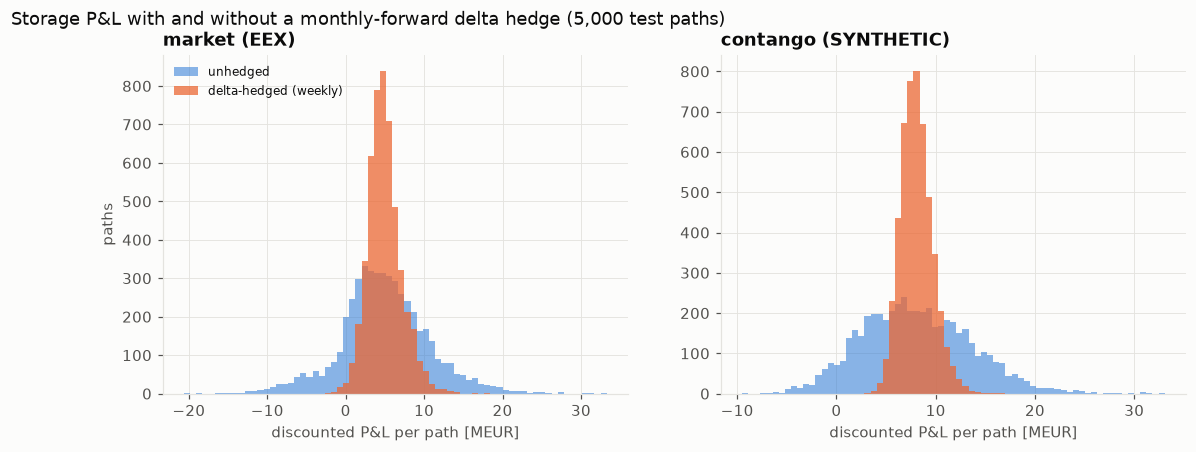

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, CASES, strict=True):
    res = hedges[(name, "weekly", 0.0)]
    bins = (
        np.linspace(
            min(res.unhedged.min(), res.hedged.min()), max(res.unhedged.max(), res.hedged.max()), 70
        )
        / 1e6
    )
    ax.hist(res.unhedged / 1e6, bins=bins, color=plotting.SERIES[0], alpha=0.55, label="unhedged")
    ax.hist(
        res.hedged / 1e6,
        bins=bins,
        color=plotting.SERIES[1],
        alpha=0.75,
        label="delta-hedged (weekly)",
    )
    ax.set_title(name)
    ax.set_xlabel("discounted P&L per path [MEUR]")
axes[0].set_ylabel("paths")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle(
    "Storage P&L with and without a monthly-forward delta hedge (5,000 test paths)",
    x=0.01,
    ha="left",
)
plotting.save_figure(fig, "05_hedged_pnl")
fig

**Cross-check: envelope delta vs bump delta at the valuation date.** The hedge's initial position comes from
the envelope regression, the greeks from bump-and-revalue: two different estimators of the same derivative.
The envelope delta is converted to $\partial V/\partial F_m$ by multiplying by $D_m$.

In [9]:
name = "market (EEX)"
res = hedges[(name, "monthly", 0.0)]
inp_ = inputs[name]
first = np.array([np.argmax(inp_.dates.to_period("M") == m) for m in res.initial_delta.index])
cmp = pd.DataFrame(
    {
        "envelope [GWh]": res.initial_delta.to_numpy() * inp_.discount[first] / 1e3,
        "bump [GWh]": greeks[name].deltas.reindex(res.initial_delta.index)["delta_mwh"].to_numpy()
        / 1e3,
        "bump SE [GWh]": greeks[name].deltas.reindex(res.initial_delta.index)["se"].to_numpy()
        / 1e3,
    },
    index=res.initial_delta.index,
)
cmp["difference [GWh]"] = cmp["envelope [GWh]"] - cmp["bump [GWh]"]
cmp.round(2)

,envelope [GWh],bump [GWh],bump SE [GWh],difference [GWh]
2027-04,-66.62,-59.60,3.06,-7.02
2027-05,-65.55,-67.10,3.57,1.55
2027-06,-55.90,-53.32,4.44,-2.58
2027-07,-40.62,-38.54,5.69,-2.08
2027-08,-2.01,-3.46,5.78,1.45
2027-09,31.60,22.82,6.35,8.79
2027-10,6.41,-1.02,5.93,7.43
2027-11,44.09,26.81,6.10,17.28
2027-12,104.16,110.95,6.17,-6.79
2028-01,80.03,74.05,5.09,5.98


## 4. Findings

All values discounted to 2026-11-17, weekly decisions, 101 volume levels, 5,000 + 5,000 paths, seeds fixed.

**Greeks (market case).**

* *Delta profile.* Even on a backwardated curve, the LSMC policy is on average a buyer of spring/summer 2027
  (April-July deltas of -39 to -67 GWh) and a seller of winter 2027/28 (December +111 GWh, January +74 GWh): it buys
  when the spot dips below the curve and sells into spikes, and those opportunities are skewed towards the shoulder and
  winter months. The contango case shows the same pattern, amplified by the intrinsic spread (July -179 GWh,
  December +270 GWh).
* *Parallel delta* +129 GWh (SE 3): the value grows with the level of the curve, because in a lognormal model
  absolute price swings, hence optionality, scale with the level.
* *Gamma* is not distinguishable from zero at this path count (SE larger than the estimate).
* *Vega* +120 kEUR per +0.01 of $\sigma$ (about 2.4 % of the value per volatility point), *mean reversion*
  +239 kEUR per +1/year of $\kappa$: faster reversion means more round trips that the storage can monetise within the
  year.
* *Common random numbers* are what makes these numbers usable: the parallel delta is 129 ± 3 GWh with CRN and
  -37 ± 117 GWh with independent seeds. Across three seed pairs the greeks agree within their standard errors
  (parallel delta 129 / 132 / 129 GWh, vega 120 / 123 / 121 kEUR).
* *Two estimators, one derivative.* The envelope deltas used by the hedge agree with the bump deltas within about
  two standard errors in most months (largest gap November, 17 GWh).

**Parameter risk dominates Monte Carlo risk.** With the same seeds, the market-case value is 4.99 MEUR with the
reference calibration, 4.05 without the trend ($\kappa = 2.7$), 4.78 excluding the 2026 rally, 1.16 on the full sample
($\kappa = 0.7$: shocks barely revert within the year) and 10.97 with crisis volatility ($\sigma = 1.23$). The
calibration window moves the value by far more than the 0.08 MEUR standard error; this is the main caveat of the
valuation and the reason to calibrate to market (option-implied) volatility and to a term structure of forward
volatilities when such data is available.

**Delta hedging (market case).** Monthly forwards rebalanced weekly cut the standard deviation of the discounted P&L
from 5.69 to 2.14 MEUR (-62 %; -60 % with monthly rebalancing) without changing its mean (4.97 MEUR) when trading is
free. The 95 % VaR goes from a 4.65 MEUR loss to no loss (the hedged 5 % quantile is a gain of 1.86 MEUR). With an
illustrative 0.10 EUR/MWh bid-ask spread, costs reduce the mean by about 0.10 MEUR (monthly) and 0.19 MEUR (weekly)
for a marginal extra variance reduction: here monthly rebalancing is the better trade-off. The contango case behaves
the same way (-71 %).

**What the hedge cannot remove.** About 2.1 MEUR of standard deviation remains: the spot exposure inside each
delivery month (monthly forwards stop trading at the start of the month), the discrete rebalancing, and the
regression error of the hedge ratio. Hedging with daily (day-ahead / balance-of-month) products, or optimising the
hedge directly under transaction costs, are the natural next steps; the second is the subject of my companion
repository `deep-hedging-transaction-costs`.